<a href="https://colab.research.google.com/github/SouridyaDey/credit-risk-modelling-for-loan-default/blob/master/Credit_risk_modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CREDIT RISK MODELLING FOR LOAN DEFAULTERS

## Objective: To develop a model to predict the probability of default (PD) for mortgage loan applicants, enabling automatic rejection of high-risk applicants.
.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import warnings
warnings.filterwarnings('ignore', category = FutureWarning)

### Loading the dataset

In [2]:
df = pd.read_csv('d:\Datasets\Quant_Challenge_data_amended.csv')

<>:1: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:1: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\Souridya\AppData\Local\Temp\ipykernel_19148\997005410.py:1: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  df = pd.read_csv('d:\Datasets\Quant_Challenge_data_amended.csv')


In [3]:
df.head(20)

,Unnamed: 0,income,loan_amount,term_length,install_to_inc,occup,marital,schufa,num_applic,OBS_DATE,target_var,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,0,18785.51794,12300,67,0.009772533,NaN,Single,7106.014471,1,18JUL2018 - 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,12861.49516,Not avail.,113,0.003509137,Employee,Divorced,7694.806894,1,16JUL2018 - 00:00:00,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2,14886.77634,10700,Not avail.,0.013310346,Worker,Single,7142.496338,1,21DEC2010 - 00:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN
3,3,Not avail.,33000,112,0.004760875,Employee,Single,7446.170612,1,05NOV2015 - 00:00:00,0,NaN,NaN,NaN,NaN,NaN,NaN
4,4,15897.75381,19900,59,0.021216087,Worker,Separated,7241.656646,1,13JUL2015 - 00:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN
5,5,30494.61964,28500,38,0.024594503,Worker,Divorced,6566.899667,1,25JAN2016 - 00:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN
6,6,34720.70255,NaN,75,Not avail.,Worker,Single,14731.8093,1,10APR2014 - 00:00:00,0,NaN,NaN,NaN,NaN,NaN,NaN
7,7,31606.20267,14000,122,0.003630746,Employee,Single,7075.138486,1,19FEB2015 - 00:00:00,0,NaN,NaN,NaN,NaN,NaN,NaN
8,8,35963.2563,Not avail.,103,0.004589366,Employee,Separated,9069.076779,1,28MAR2017 - 00:00:00,0,NaN,NaN,NaN,NaN,NaN,NaN
9,9,39686.88094,16200,85,0.004802298,Employee,Married,10278.35272,2,11SEP2010 - 00:00:00,0,NaN,NaN,NaN,NaN,NaN,NaN


### Display the rows and columns

In [4]:
df.shape

(10000, 17)

### Remove the first column 'Unnamed:0' which is not necessary

In [5]:
cols_to_remove = ["Unnamed: 0"]

for i in range(11, 17):

    cols_to_remove.append(f"Unnamed: {i}")

print(cols_to_remove)
df.drop(columns=cols_to_remove, inplace=True)

['Unnamed: 0', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16']


C:\Users\Souridya\AppData\Local\Temp\ipykernel_19148\2923681715.py:8: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=cols_to_remove, inplace=True)


In [6]:
df.sample(5)

,income,loan_amount,term_length,install_to_inc,occup,marital,schufa,num_applic,OBS_DATE,target_var
640,16419.51463,17800,28,0.038716996,Student,Single,9443.521334,1,05AUG2013 - 00:00:00,0
9074,34593.74215,21500,134,NaN,Employee,Married,NaN,1,18MAR2011 - 00:00:00,0
7804,22047.40874,10700,112,0.004333195,Employee,Not avail.,7843.906111,1,26FEB2016 - 00:00:00,0
6352,27461.76703,20400,28,0.026530391,Not avail.,Single,7792.794249,1,05FEB2009 - 00:00:00,0
2639,30915.3417,32400,83,0.012626787,Employee,NaN,6049.999892,1,03AUG2015 - 00:00:00,0


### Checking for duplicates

In [7]:
df.duplicated().any()

np.False_

In [8]:
df['OBS_DATE'].nunique()

3602

### Separating the training and Out-of-test (OOT), which will serve as our unseen data.

### Any data collected between 2016-2018 will serve as OOT data

In [9]:
# Converting OBS_DATE to datetime format
df['OBS_DATE'] = pd.to_datetime(df['OBS_DATE'], format="%d%b%Y - %H:%M:%S", errors="coerce")

In [10]:
df.sample(5)

,income,loan_amount,term_length,install_to_inc,occup,marital,schufa,num_applic,OBS_DATE,target_var
8255,NaN,NaN,131,0.004951947,Not avail.,NaN,6832.914849,1,2017-08-07,0
7653,21202.21354,NaN,70,0.007883274,Worker,Separated,7688.200152,1,2013-05-15,0
3499,25096.7491,35500,29,0.048776753,Student,Separated,8678.623201,1,2017-05-26,0
6130,22831.43729,17800,55,0.014175032,Worker,Single,9616.565973,1,2011-09-07,0
4301,11960.48146,26900,83,0.027097269,Student,Single,6856.289097,1,2014-06-13,0


In [11]:

# Define date range for OOT sample
oot_start = pd.to_datetime("2016-01-01")
oot_end = pd.to_datetime("2018-12-31")

# Creating boolean masks for training and OOT data
oot_mask = (df['OBS_DATE'] >= oot_start) & (df['OBS_DATE'] <= oot_end)
train_mask = df['OBS_DATE'] < oot_start

# Filter the DataFrame using the masks
df_train = df[train_mask].copy()
df_oot = df[oot_mask].copy()

# Print the size of each set
print("Training set size:", df_train.shape)
print("OOT set size:", df_oot.shape)


Training set size: (6803, 10)
OOT set size: (2632, 10)


### Removing the 'observation date' column
##### It is now of no need as we have already separated our dataset based on time

In [12]:
df_train.drop(columns=['OBS_DATE'], inplace=True)
df_oot.drop(columns=['OBS_DATE'], inplace=True)

C:\Users\Souridya\AppData\Local\Temp\ipykernel_19148\3302619054.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_train.drop(columns=['OBS_DATE'], inplace=True)
C:\Users\Souridya\AppData\Local\Temp\ipykernel_19148\3302619054.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_oot.drop(columns=['OBS_DATE'], inplace=True)


In [13]:
df_train.head(20)

,income,loan_amount,term_length,install_to_inc,occup,marital,schufa,num_applic,target_var
2,14886.77634,10700,Not avail.,0.013310346,Worker,Single,7142.496338,1,1
3,Not avail.,33000,112,0.004760875,Employee,Single,7446.170612,1,0
4,15897.75381,19900,59,0.021216087,Worker,Separated,7241.656646,1,1
6,34720.70255,NaN,75,Not avail.,Worker,Single,14731.8093,1,0
7,31606.20267,14000,122,0.003630746,Employee,Single,7075.138486,1,0
9,39686.88094,16200,85,0.004802298,Employee,Married,10278.35272,2,0
11,40859.61061,14600,47,0.007602576,2,Married,6248.914404,NaN,Not avail.
12,17186.18424,17800,53,0.019541805,Worker,Single,11850.81965,1,0
13,16173.57326,25600,40,0.039570724,Worker,Divorced,9161.013171,1,0
14,Not avail.,11800,75,0.00558706,Worker,Living together,7533.469389,1,0


### Some descriptive measures

In [14]:
df_train.info()

<class 'pandas.DataFrame'>
Index: 6803 entries, 2 to 9999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   income          6602 non-null   str  
 1   loan_amount     6585 non-null   str  
 2   term_length     6582 non-null   str  
 3   install_to_inc  6591 non-null   str  
 4   occup           6587 non-null   str  
 5   marital         6614 non-null   str  
 6   schufa          6609 non-null   str  
 7   num_applic      6599 non-null   str  
 8   target_var      6608 non-null   str  
dtypes: str(9)
memory usage: 909.9 KB


In [15]:
df_train.describe()

,income,loan_amount,term_length,install_to_inc,occup,marital,schufa,num_applic,target_var
count,6602,6585,6582,6591,6587,6614,6609,6599,6608
unique,6383,380,163,6397,7,6,6381,3,3
top,Not avail.,Not avail.,Not avail.,Not avail.,Worker,Single,Not avail.,1,0
freq,220,213,174,195,3076,2603,229,4521,5449


In [16]:
df_train["schufa"].min()

'10000.04893'

### Checking for any missing values

In [17]:
print(df_train.isnull().sum())
print(df_oot.isnull().sum())





income            201
loan_amount       218
term_length       221
install_to_inc    212
occup             216
marital           189
schufa            194
num_applic        204
target_var        195
dtype: int64
income            91
loan_amount       73
term_length       77
install_to_inc    71
occup             81
marital           93
schufa            74
num_applic        89
target_var        63
dtype: int64


In [18]:
print(df_train['target_var'].value_counts())
print(df_oot['target_var'].value_counts())

target_var
0             5449
1              973
Not avail.     186
Name: count, dtype: int64
target_var
0             2084
1              395
Not avail.      90
Name: count, dtype: int64


### Replacing Not avail. with NaN to help in imputation later

In [19]:
df_train.replace("Not avail.", np.nan, inplace=True)
df_oot.replace("Not avail.", np.nan, inplace=True)

,income,loan_amount,term_length,install_to_inc,occup,marital,schufa,num_applic,target_var
0,18785.51794,12300,67,0.009772533,NaN,Single,7106.014471,1,NaN
1,12861.49516,NaN,113,0.003509137,Employee,Divorced,7694.806894,1,0
5,30494.61964,28500,38,0.024594503,Worker,Divorced,6566.899667,1,1
8,35963.2563,NaN,103,0.004589366,Employee,Separated,9069.076779,1,0
10,8298.012136,16100,42,0.046195803,Worker,Single,7109.577583,1,1
...,...,...,...,...,...,...,...,...,...
9975,18575.35464,NaN,62,0.017192395,Worker,NaN,10923.7899,2,0
9979,8334.157375,7900,92,0.010303329,Student,NaN,12690.48235,1,0
9993,13159.3905,10100,50,0.015350255,Worker,Single,8689.654573,1,1
9995,23743.2986,21900,66,0.013975235,Worker,Single,9703.314402,1,0


### This will ignore any leftover strings

In [20]:
df_oot["schufa"].max()

'9998.399555'

In [21]:
df_train['target_var'] = pd.to_numeric(df_train['target_var'], errors='coerce')
df_oot['target_var'] = pd.to_numeric(df_oot['target_var'], errors='coerce')

### Filling Nan records with 0: defaulters in our target column

##### Since we don't have the default information about the missing records, we make them fall under Non-defaulters class: 0

In [22]:
df_train['target_var'] = df_train['target_var'].fillna(0)
df_oot['target_var'] = df_oot['target_var'].fillna(0)

### Distribution of defaulters and non-defaulters

In [23]:
class_names = {0:'Non-defaulter', 1:'Defaulter'}
print(df_train['target_var'].value_counts().rename(index = class_names))

target_var
Non-defaulter    5830
Defaulter         973
Name: count, dtype: int64


### To ensure that numeric columns are not mistakenly stored as strings

In [24]:
print(df_train["schufa"].dtype)
print(df_train["schufa"].head())

str
2    7142.496338
3    7446.170612
4    7241.656646
6     14731.8093
7    7075.138486
Name: schufa, dtype: str


In [25]:
# Step 2: Find the values that can't be converted to numbers
converted = pd.to_numeric(df_train["schufa"], errors="coerce")
bad_values = df_train["schufa"][converted.isna() & df_train["schufa"].notna()]
print(bad_values.unique())

<ArrowStringArray>
[]
Length: 0, dtype: str


In [26]:
# Step 3: Convert the column once you know what's in it
df_train["schufa"] = pd.to_numeric(df_train["schufa"], errors="coerce")
df_oot["schufa"] = pd.to_numeric(df_oot["schufa"], errors="coerce")

In [27]:
print(df_train["schufa"].isna().sum(), "missing values after conversion")


423 missing values after conversion


In [28]:
print(df_train["schufa"].dtype)   # expect float64
print(df_oot["schufa"].dtype)     # expect float64

float64
float64


In [29]:
num_cols = ['income', 'loan_amount', 'term_length', 'install_to_inc', 'schufa', 'num_applic', 'target_var']

for col in num_cols:
    df_train[col] = pd.to_numeric(df_train[col])
    df_oot[col] = pd.to_numeric(df_oot[col])

In [30]:
print(df_train["schufa"].describe())
print(df_oot["schufa"].describe())

count     6380.000000
mean      8841.479452
std       2039.965030
min       6001.367395
25%       7258.677176
50%       8429.996113
75%       9927.704593
max      14843.617740
Name: schufa, dtype: float64
count     2495.000000
mean      8685.772789
std       1993.680497
min       6000.156943
25%       7180.415473
50%       8253.939264
75%       9719.533086
max      14819.830730
Name: schufa, dtype: float64


In [31]:
df_train.info()

<class 'pandas.DataFrame'>
Index: 6803 entries, 2 to 9999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   income          6382 non-null   float64
 1   loan_amount     6372 non-null   float64
 2   term_length     6408 non-null   float64
 3   install_to_inc  6396 non-null   float64
 4   occup           6384 non-null   str    
 5   marital         6393 non-null   str    
 6   schufa          6380 non-null   float64
 7   num_applic      6405 non-null   float64
 8   target_var      6803 non-null   float64
dtypes: float64(7), str(2)
memory usage: 625.9 KB


In [32]:
df_train.describe()


,income,loan_amount,term_length,install_to_inc,schufa,num_applic,target_var
count,6382.000000,6372.000000,6408.000000,6396.000000,6380.000000,6405.000000,6803.000000
mean,27130.830160,20444.460138,65.411205,0.020992,8841.479452,1.294145,0.143025
std,12659.967944,7432.655788,30.869188,0.024989,2039.965030,0.455693,0.350124
min,5049.371296,5100.000000,12.000000,0.000729,6001.367395,1.000000,0.000000
25%,17412.120225,14900.000000,41.000000,0.007316,7258.677176,1.000000,0.000000
50%,25953.007590,20200.000000,63.000000,0.012717,8429.996113,1.000000,0.000000
75%,35417.083507,25500.000000,86.000000,0.024705,9927.704593,2.000000,0.000000
max,81215.721990,48000.000000,214.000000,0.394223,14843.617740,2.000000,1.000000


In [33]:
df_oot.describe()

,income,loan_amount,term_length,install_to_inc,schufa,num_applic,target_var
count,2466.000000,2473.000000,2485.000000,2494.000000,2495.000000,2462.000000,2632.000000
mean,27347.246085,20516.659927,65.140443,0.020810,8685.772789,1.283916,0.150076
std,12567.809222,7606.984357,30.575926,0.023067,1993.680497,0.450988,0.357214
min,5021.691061,5100.000000,12.000000,0.001153,6000.156943,1.000000,0.000000
25%,17666.297845,14900.000000,41.000000,0.007380,7180.415473,1.000000,0.000000
50%,26566.722650,20100.000000,64.000000,0.013045,8253.939264,1.000000,0.000000
75%,35589.690630,25800.000000,86.000000,0.024394,9719.533086,2.000000,0.000000
max,77952.582310,50300.000000,182.000000,0.242869,14819.830730,2.000000,1.000000


### Checking the skewness for each features
##### This will help us decide whether to go for median imputation or something else.

In [34]:
# List of numeric columns
numeric_columns = ['income', 'loan_amount', 'term_length', 'install_to_inc', 'schufa', 'num_applic']

# Convert columns to numeric (if not already)
for col in numeric_columns:
    df_train[col] = pd.to_numeric(df_train[col], errors='coerce')

# Loop to calculate and print skewness
for col in numeric_columns:
    skew_val = df_train[col].skew()
    print(f"Skewness of '{col}': {skew_val:.2f}")


Skewness of 'income': 0.48
Skewness of 'loan_amount': 0.27
Skewness of 'term_length': 0.50
Skewness of 'install_to_inc': 4.09
Skewness of 'schufa': 0.92
Skewness of 'num_applic': 0.90


##### Since, most of them are almost close to 1, it is safe to go for median imputation for the numerical features

In [35]:
df_train['occup'].value_counts()

occup
Worker      3076
Employee    1882
Student     1236
2             69
1             65
3             56
Name: count, dtype: int64

In [36]:
df_train['marital'].value_counts()

marital
Single             2603
Separated           976
Married             950
Living together     946
Divorced            918
Name: count, dtype: int64

### Replacing extra categorical features of 'Occupation' column with 'Others'

In [37]:
# Ensure 'occup' column is in the correct format (string type)
df_train['occup'] = df_train['occup'].astype(str)
df_oot['occup'] = df_oot['occup'].astype(str)

# Replace 1, 2, 3 with 'Others'
df_train['occup'] = df_train['occup'].replace({'1': 'Others', '2': 'Others', '3': 'Others'})
df_oot['occup'] = df_oot['occup'].replace({'1': 'Others', '2': 'Others', '3': 'Others'})

In [38]:
df_train['occup'].value_counts()

occup
Worker      3076
Employee    1882
Student     1236
Others       190
Name: count, dtype: int64

### Checking for Outliers with boxplot

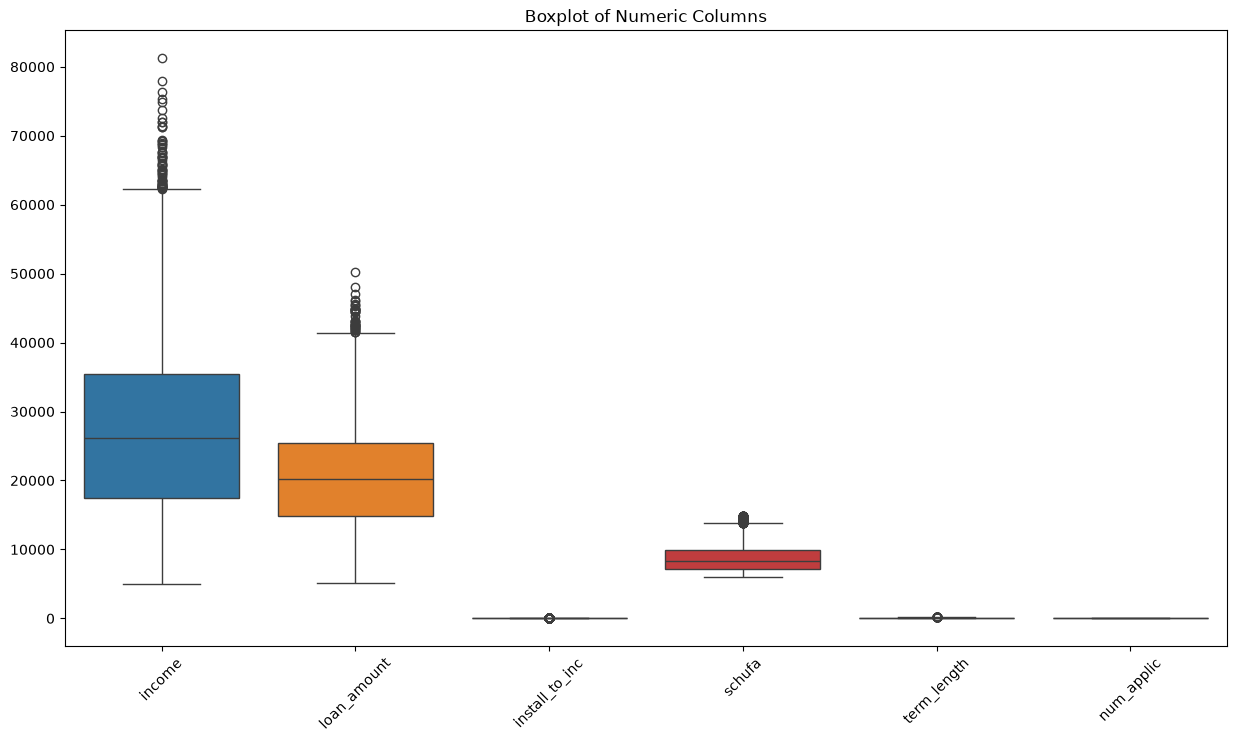

In [39]:
# Select numeric columns
numeric_cols = ['income', 'loan_amount', 'install_to_inc', 'schufa', 'term_length', 'num_applic']

plt.figure(figsize=(15, 8))
df_numeric = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

# Use seaborn to plot
sns.boxplot(data=df_numeric)

plt.title('Boxplot of Numeric Columns')
plt.xticks(rotation=45)
plt.show()

### Detecting outliers based on quantile method

In [40]:
numeric_cols = ['income', 'loan_amount', 'install_to_inc', 'schufa', 'term_length', 'num_applic']

outlier_counts = {}

for col in numeric_cols:
    lower_bound = df_train[col].quantile(0.01)
    upper_bound = df_train[col].quantile(0.99)
    outliers = df_train[(df_train[col] < lower_bound) | (df_train[col] > upper_bound)]
    outlier_counts[col] = outliers.shape[0]

# Display the outlier counts
for col, count in outlier_counts.items():
    print(f"{col}: {count} outliers (based on 1st and 99th percentiles)")

income: 128 outliers (based on 1st and 99th percentiles)
loan_amount: 127 outliers (based on 1st and 99th percentiles)
install_to_inc: 128 outliers (based on 1st and 99th percentiles)
schufa: 128 outliers (based on 1st and 99th percentiles)
term_length: 128 outliers (based on 1st and 99th percentiles)
num_applic: 0 outliers (based on 1st and 99th percentiles)


### Though there are some extreme values, but they shouldn't be treated as outliers.

##### Income and loan amount could be high in some cases as it reflects real life data

### Separating Dependent and independent variables

In [41]:
# Separating  features and target for training
X_train = df_train.drop(columns=['target_var'], errors = 'ignore')
y_train = df_train['target_var']

# Same for OOT set
X_oot = df_oot.drop(columns=['target_var'], errors = 'ignore')
y_oot = df_oot['target_var']

In [42]:
X_train.head()

,income,loan_amount,term_length,install_to_inc,occup,marital,schufa,num_applic
2,14886.77634,10700.0,NaN,0.013310,Worker,Single,7142.496338,1.0
3,NaN,33000.0,112.0,0.004761,Employee,Single,7446.170612,1.0
4,15897.75381,19900.0,59.0,0.021216,Worker,Separated,7241.656646,1.0
6,34720.70255,NaN,75.0,NaN,Worker,Single,14731.809300,1.0
7,31606.20267,14000.0,122.0,0.003631,Employee,Single,7075.138486,1.0


In [43]:
y_train.head()

2    1.0
3    0.0
4    1.0
6    0.0
7    0.0
Name: target_var, dtype: float64

In [44]:
print(X_train.shape)
print(X_oot.shape)
print(y_train.shape)
print(y_oot.shape)

(6803, 8)
(2632, 8)
(6803,)
(2632,)


### Implementing Missing value imputation, OHE and Scaling with the help of pipeline

In [45]:
# Define categorical columns (OHE) and let others be numeric
cat_cols = ['occup', 'marital']
num_cols = [col for col in X_train.columns if col not in cat_cols]  # auto-identify numeric



In [46]:
# Create a sub-pipeline for numeric features (Impute only)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

##### For categorical features, we have imputed the missing value with 'Not available' as we have no prior information and imputing with some value might affect the data

In [47]:
# Create a sub-pipeline for categorical features (Impute -> Encode)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Not available')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

In [48]:
# Combine both sub-pipelines into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ]
)

In [49]:
# Create the final pipeline (Preprocess -> Scale)
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('scale', StandardScaler())
])

### 'Fit_transformed' on training data and only 'transformed' on OOT data just to see how well our model performs on unseen data

In [50]:
X_train_preprocessed = pipeline.fit_transform(X_train)
X_oot_preprocessed = pipeline.transform(X_oot)

### Retrieve the feature names

In [51]:
# Get OHE feature names
ohe_feature_names = pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(cat_cols)

# Combine with numeric column names (these are passed through)
all_feature_names = list(ohe_feature_names) + num_cols

print(all_feature_names)


['occup_Not available', 'occup_Others', 'occup_Student', 'occup_Worker', 'marital_Living together', 'marital_Married', 'marital_Not available', 'marital_Separated', 'marital_Single', 'income', 'loan_amount', 'term_length', 'install_to_inc', 'schufa', 'num_applic']


### Create the dataframe with all the feature names

In [52]:
# Rebuild DataFrames with proper names
X_train_preprocessed = pd.DataFrame(X_train_preprocessed, columns=all_feature_names, index=X_train.index)
X_oot_preprocessed= pd.DataFrame(X_oot_preprocessed, columns=all_feature_names, index=X_oot.index)

In [53]:
X_train_preprocessed.head()

,occup_Not available,occup_Others,occup_Student,occup_Worker,marital_Living together,marital_Married,marital_Not available,marital_Separated,marital_Single,income,loan_amount,term_length,install_to_inc,schufa,num_applic
2,-0.992405,-1.352554,-0.075801,-0.295656,-0.846061,-0.618874,-0.256189,-0.169503,-0.471193,1.100745,-0.401891,-0.402877,-0.253244,-0.409263,1.270245
3,-0.090093,1.747665,1.559572,-0.647381,-0.692525,-0.618874,-0.256189,-0.169503,-0.471193,-0.908476,-0.401891,-0.402877,-0.253244,-0.409263,1.270245
4,-0.909973,-0.073539,-0.209301,0.029586,-0.795926,-0.618874,-0.256189,-0.169503,-0.471193,1.100745,-0.401891,-0.402877,-0.253244,2.443417,-0.787250
6,0.624802,-0.031833,0.324698,-0.320078,2.991055,-0.618874,-0.256189,-0.169503,-0.471193,1.100745,-0.401891,-0.402877,-0.253244,-0.409263,1.270245
7,0.370853,-0.893777,1.893321,-0.693874,-0.880117,-0.618874,-0.256189,-0.169503,-0.471193,-0.908476,-0.401891,-0.402877,-0.253244,-0.409263,1.270245


In [54]:
X_train_preprocessed.shape

(6803, 15)

In [55]:
X_oot_preprocessed.head()

,occup_Not available,occup_Others,occup_Student,occup_Worker,marital_Living together,marital_Married,marital_Not available,marital_Separated,marital_Single,income,loan_amount,term_length,install_to_inc,schufa,num_applic
0,-0.674512,-1.130116,0.057699,-0.441201,-0.864506,-0.618874,3.903367,-0.169503,-0.471193,-0.908476,-0.401891,-0.402877,-0.253244,-0.409263,1.270245
1,-1.157542,-0.031833,1.592947,-0.698877,-0.566816,-0.618874,-0.256189,-0.169503,-0.471193,-0.908476,-0.401891,-0.402877,-0.253244,-0.409263,-0.787250
5,0.280218,1.122061,-0.910175,0.168574,-1.137080,-0.618874,-0.256189,-0.169503,-0.471193,1.100745,-0.401891,-0.402877,-0.253244,-0.409263,-0.787250
8,0.726116,-0.031833,1.259197,-0.654436,0.128008,-0.618874,-0.256189,-0.169503,-0.471193,-0.908476,-0.401891,-0.402877,-0.253244,2.443417,-0.787250
10,-1.529636,-0.601828,-0.776675,1.057250,-0.862704,-0.618874,-0.256189,-0.169503,-0.471193,1.100745,-0.401891,-0.402877,-0.253244,-0.409263,1.270245


### Calculating VIF to check for multicollinearity

In [56]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Add a constant (intercept) to the dataframe for accurate VIF calculation
X_vif = sm.add_constant(X_train_preprocessed)

vif = []
for i in range(X_vif.shape[1]):
    vif.append(variance_inflation_factor(X_vif.values, i))

vif_df = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF': vif
}).sort_values(by='VIF', ascending=False).reset_index(drop=True)

print(vif_df)


                    Feature       VIF
0            marital_Single  2.998908
1                    income  2.850654
2             occup_Student  2.828173
3                num_applic  2.439390
4               term_length  2.199093
5       occup_Not available  2.043762
6              occup_Worker  2.029574
7               loan_amount  1.962938
8                    schufa  1.770539
9              occup_Others  1.399984
10           install_to_inc  1.385873
11    marital_Not available  1.346347
12          marital_Married  1.237090
13        marital_Separated  1.157172
14  marital_Living together  1.001933
15                    const  1.000000


### Here the VIF of all features are less than 3 so there is no issue of multicollinearity

In [57]:
X_train_preprocessed.shape

(6803, 15)

In [58]:
X_oot_preprocessed.shape

(2632, 15)

In [59]:
X_train["occup"].value_counts()

occup
Worker      3076
Employee    1882
Student     1236
Others       190
Name: count, dtype: int64

### Model training

In [60]:
X_train["marital"].value_counts()

marital
Single             2603
Separated           976
Married             950
Living together     946
Divorced            918
Name: count, dtype: int64

## 1.Logistic Regression

In [61]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()
clf.fit(X_train_preprocessed, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [62]:
y_pred = clf.predict(X_oot_preprocessed)

### Evaluating the performance of our fitted model on OOT sample

In [63]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
print(confusion_matrix(y_oot, y_pred))
print(classification_report(y_oot, y_pred))

[[2140   97]
 [ 201  194]]
              precision    recall  f1-score   support

         0.0       0.91      0.96      0.93      2237
         1.0       0.67      0.49      0.57       395

    accuracy                           0.89      2632
   macro avg       0.79      0.72      0.75      2632
weighted avg       0.88      0.89      0.88      2632



### There is a case of class imbalance as evident by looking at the support

### The recall for defaulters (1) is very low which is our main concern here. So we need to improve this

### Now, fitting a Logistic Regression considering the case of class imbalance. Here the model is tuned via class weights to favour recall for minority class, which is good for assessing credit risk.

### Also, hyperparameter tuning with different hyperparameters have been done with 5-fold cross-validation using GridSearchCV

In [64]:
from sklearn.model_selection import GridSearchCV

# Add your model to the end of the pipeline we created earlier
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('scale', StandardScaler()),
    ('model', LogisticRegression()) 
])

# '__' tells GridSearchCV which step in the pipeline the hyperparameters belong to.
param_grid_lr = {
   'model__penalty': ['l1', 'l2'],
   'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
   'model__solver': ['liblinear'],
   'model__class_weight': ['balanced']
}

lr_grid = GridSearchCV(lr_pipeline, param_grid_lr, scoring='roc_auc', cv=5, n_jobs=-1)

# Fit using the unprocessed training data
lr_grid.fit(X_train, y_train)

print(lr_grid.best_params_)

{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__penalty': 'l1', 'model__solver': 'liblinear'}


d:\credit-risk-modelling\cred_mod_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [65]:
# Predicting on training and OOT sets
y_train_pred = lr_grid.predict(X_train)
y_oot_pred = lr_grid.predict(X_oot)

# Predicted probabilities
y_train_proba = lr_grid.predict_proba(X_train)[:, 1]
y_oot_proba = lr_grid.predict_proba(X_oot)[:, 1]

# Gini = 2 * AUC - 1
gini_train = 2 * roc_auc_score(y_train, y_train_proba) - 1
gini_oot = 2 * roc_auc_score(y_oot, y_oot_proba) - 1

# Evaluating performance
print("TRAIN SET EVALUATION:")
print(confusion_matrix(y_train, y_train_pred))
print(classification_report(y_train, y_train_pred))
print("ROC-AUC:", roc_auc_score(y_train, y_train_proba ))
print("Gini (Train):", round(gini_train, 4))

print("\nOOT SET EVALUATION:")
print(confusion_matrix(y_oot, y_oot_pred))
print(classification_report(y_oot, y_oot_pred))
print("ROC-AUC:", roc_auc_score(y_oot,y_oot_proba ))
print("Gini (OOT):", round(gini_oot, 4))

TRAIN SET EVALUATION:
[[4717 1113]
 [ 119  854]]
              precision    recall  f1-score   support

         0.0       0.98      0.81      0.88      5830
         1.0       0.43      0.88      0.58       973

    accuracy                           0.82      6803
   macro avg       0.70      0.84      0.73      6803
weighted avg       0.90      0.82      0.84      6803

ROC-AUC: 0.9221611292196332
Gini (Train): 0.8443

OOT SET EVALUATION:
[[1799  438]
 [  56  339]]
              precision    recall  f1-score   support

         0.0       0.97      0.80      0.88      2237
         1.0       0.44      0.86      0.58       395

    accuracy                           0.81      2632
   macro avg       0.70      0.83      0.73      2632
weighted avg       0.89      0.81      0.83      2632

ROC-AUC: 0.9175353519349491
Gini (OOT): 0.8351


### Here, our recall for class 1 has improved a lot which is good as our model can correctly predict 86% defaulters on unseen data.

### In credit scoring, a Gini above 0.6 is typically considered good. At 0.83, the model is highly predictive and likely performs very well in separating high-risk and low-risk applicants.

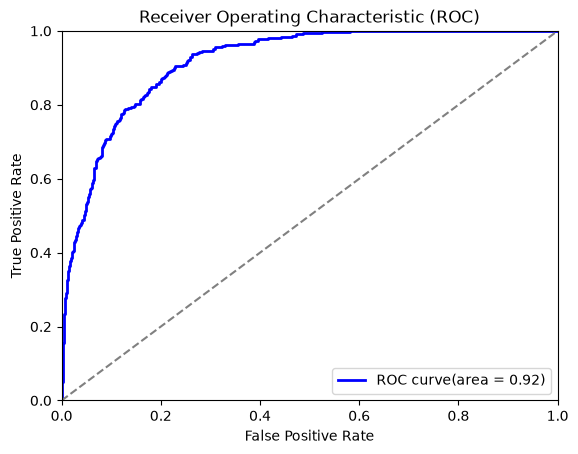

In [66]:
# plotting the ROC-AUC curve
fpr, tpr, _ = roc_curve(y_oot, y_oot_proba)
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label= 'ROC curve(area = %0.2f)' % roc_auc_score(y_oot, y_oot_proba))
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line for random guessing
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.show()

### A score of 0.92 indicates excellent discrimination — the model correctly ranks defaulters vs. non-defaulters 92% of the time.

### Now, we proceed with two key tools used to evaluate effectiveness of our Credit Decisioning Model

### Deciling

In [67]:
#Creating DataFrames for train and OOT with predicted probabilities and actual target
train_results = pd.DataFrame({
    'probability': y_train_proba,
    'target': y_train
})

oot_results = pd.DataFrame({
    'probability': y_oot_proba,
    'target': y_oot
})

#Creating deciles based on training data
quantiles = train_results['probability'].quantile(np.linspace(0, 1, 11)).values  # 11 bin edges for 10 deciles

#Assigning deciles to training data
train_results['decile'] = pd.cut(train_results['probability'], bins=quantiles, labels=False, include_lowest=True)
train_results['decile'] = 10 - train_results['decile']  # Decile 1 = highest prob

#Assigning same decile cutoffs to OOT data
oot_results['decile'] = pd.cut(oot_results['probability'], bins=quantiles, labels=False, include_lowest=True)
oot_results['decile'] = 10 - oot_results['decile']

#Summarizing  training data
train_summary = train_results.groupby('decile').agg(
    number_of_applicants=('target', 'count'),
    number_of_defaulters=('target', 'sum'),
    Default_rate=('target', 'mean')
).reset_index().sort_values('decile')
train_summary['Default_rate'] = (train_summary['Default_rate'] * 100).round(2)

#Summarizing OOT data
oot_summary = oot_results.groupby('decile').agg(
    number_of_applicants=('target', 'count'),
    number_of_defaulters=('target', 'sum'),
    Default_rate=('target', 'mean')
).reset_index().sort_values('decile')
oot_summary['Default_rate'] = (oot_summary['Default_rate'] * 100).round(2)


In [74]:
print(quantiles)

[4.25626200e-07 1.32717130e-03 8.74587231e-03 2.85110296e-02
 7.20674990e-02 1.53391162e-01 2.82517263e-01 4.76550489e-01
 6.84974804e-01 8.59692807e-01 9.96220399e-01]


### Table showing the deciles, number of loan applicants, number of defaulters, and the default % in training data

In [68]:
print(train_summary)

   decile  number_of_applicants  number_of_defaulters  Default_rate
0       1                   681                 466.0         68.43
1       2                   680                 263.0         38.68
2       3                   680                 136.0         20.00
3       4                   680                  66.0          9.71
4       5                   680                  29.0          4.26
5       6                   681                  10.0          1.47
6       7                   680                   3.0          0.44
7       8                   680                   0.0          0.00
8       9                   680                   0.0          0.00
9      10                   681                   0.0          0.00


### Table showing the deciles, number of loan applicants, number of defaulters, and the default % in OOT data

In [69]:
print(oot_summary)

   decile  number_of_applicants  number_of_defaulters  Default_rate
0       1                   284                 192.0         67.61
1       2                   246                 100.0         40.65
2       3                   283                  55.0         19.43
3       4                   267                  31.0         11.61
4       5                   265                   9.0          3.40
5       6                   242                   7.0          2.89
6       7                   263                   1.0          0.38
7       8                   273                   0.0          0.00
8       9                   282                   0.0          0.00
9      10                   227                   0.0          0.00


In [70]:
# Calculating Capture rates in training and oot data in top 3 deciles

cap_rate_train = (sum(train_summary['number_of_defaulters'][0:3])/sum(train_summary['number_of_defaulters']))*100
print(round(cap_rate_train, 2), '%')

cap_rate_oot = (sum(oot_summary['number_of_defaulters'][0:3])/sum(oot_summary['number_of_defaulters']))*100
print(round(cap_rate_oot, 2), '%')


88.9 %
87.85 %


### Training data has a capture rate of 88.90% and OOT data has a capture rate of 87.85% in top 3 deciles.

### Interpretation: Top 30% probability is able to capture more than 85% of all the actual defaulters both in training and out of time sample. Also, rank ordering holds true for default rate captured across deciles. Hence, model is able to capture the behaviour well.

In [73]:
# Lift calculation for top 30%

training_lift = ((466 + 263 + 136)/(681 + 680 + 680))/(973/6803)
oot_lift = ((192 + 100 + 55)/(284 + 246 + 283))/(395/2632)
print(training_lift)
print(oot_lift)

2.963198420055864
2.8439877310165507


### Interpretation: Lift in top 30% is 2.96x in training data and 2.84x in out-of-time indicating that top 30% of our model would help to capture defaulters nearly 3x better than considering random 30% of population.

### Rank Ordering plot

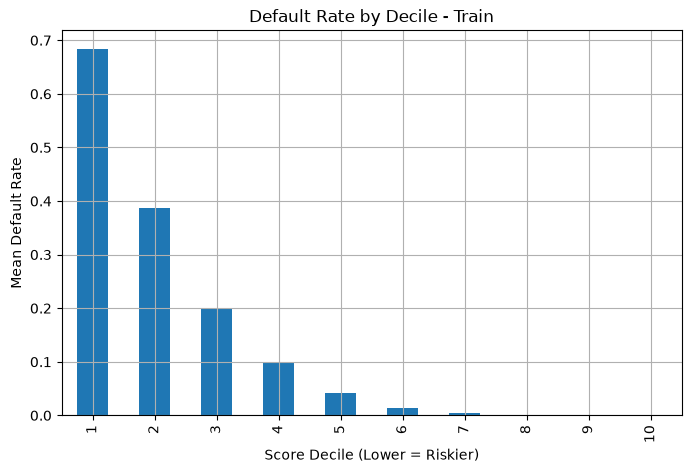

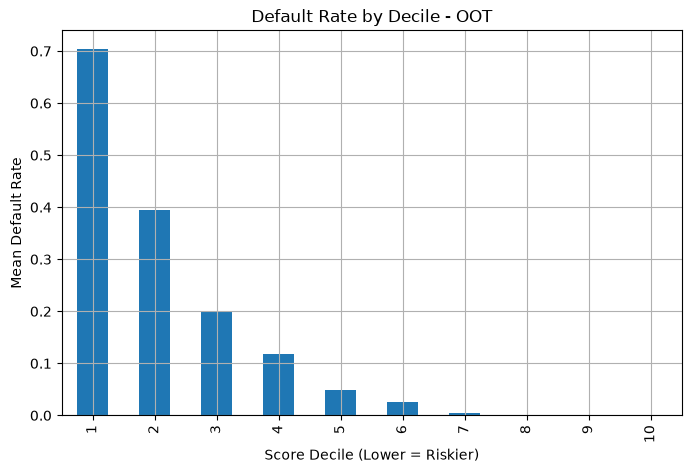

In [72]:
def rank_ordering_plot(y_true, y_proba, dataset_name='Train'):
    df = pd.DataFrame({'actual': y_true, 'proba': y_proba})
    df['decile'] = pd.qcut(df['proba'], 10, labels=False, duplicates='drop') + 1
    df['decile'] = 11 - df['decile']
    grouped = df.groupby('decile')['actual'].mean()

    plt.figure(figsize=(8, 5))
    grouped.plot(kind='bar')
    plt.title(f'Default Rate by Decile - {dataset_name}')
    plt.xlabel('Score Decile (Lower = Riskier)')
    plt.ylabel('Mean Default Rate')
    plt.grid(True)
    plt.show()

# Plots for Train and OOT
rank_ordering_plot(y_train, y_train_proba, 'Train')
rank_ordering_plot(y_oot, y_oot_proba, 'OOT')

### Decile 1 has highest probability of Default (PD) whereas Decile 10 has the lowest PD

### This helps us identify which decile (or score range) to use as a decision threshold (e.g., reject all applicants in Deciles 1-3).

### Now, we will do the same things for Balanced RF and XGBoost algorithms and evaluate the model performance.

## 2. Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

### Hyperparameter tuning

In [ ]:
from sklearn.model_selection import GridSearchCV
# Hyperparameter tuning for RF 

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
    ]
)

param_grid_rf = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [3, 5, 7],
    'model__min_samples_split': [20, 35, 50],
    'model__min_samples_leaf': [10, 20, 30],
    'model__max_features': [0.6, 0.8],
    'model__class_weight': ['balanced']
}

rf_grid = GridSearchCV(rf_pipeline, param_grid_rf, scoring='roc_auc', cv=5, n_jobs=-1)

rf_grid.fit(X_train, y_train)

print(rf_grid.best_params_)

In [ ]:

# Predicting on training and OOT sets
y_train_rf_pred = rf_grid.predict(X_train)
y_oot_rf_pred = rf_grid.predict(X_oot)

# Predicted probabilities
y_train_rf_proba = rf_grid.predict_proba(X_train)[:, 1]
y_oot_rf_proba = rf_grid.predict_proba(X_oot)[:, 1]

# Gini = 2 * AUC - 1
gini_train_rf = 2 * roc_auc_score(y_train, y_train_rf_proba) - 1
gini_oot_rf = 2 * roc_auc_score(y_oot, y_oot_rf_proba) - 1

# Evaluating performance
print("TRAIN SET EVALUATION:")
print(confusion_matrix(y_train, y_train_rf_pred))
print(classification_report(y_train, y_train_rf_pred))
print("ROC-AUC:", roc_auc_score(y_train, y_train_rf_proba ))
print("Gini (Train):", round(gini_train_rf, 4))

print("\nOOT SET EVALUATION:")
print(confusion_matrix(y_oot, y_oot_rf_pred))
print(classification_report(y_oot, y_oot_rf_pred))
print("ROC-AUC:", roc_auc_score(y_oot,y_oot_rf_proba ))
print("Gini (OOT):", round(gini_oot_rf, 4))

In [ ]:
# plotting the ROC-AUC curve
fpr, tpr, _ = roc_curve(y_oot, y_oot_rf_proba)
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label= 'ROC curve(area = %0.2f)' % roc_auc_score(y_oot, y_oot_rf_proba))
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line for random guessing
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) ')
plt.legend(loc='lower right')
plt.show()

In [ ]:
#Creating DataFrames for train and OOT with predicted probabilities and actual target
train_rf_results = pd.DataFrame({
    'probability': y_train_rf_proba,
    'target': y_train
})

oot_rf_results = pd.DataFrame({
    'probability': y_oot_rf_proba,
    'target': y_oot
})

#Creating deciles based on training data
quantiles = train_rf_results['probability'].quantile(np.linspace(0, 1, 11)).values  # 11 bin edges for 10 deciles

#Assigning deciles to training data
train_rf_results['decile'] = pd.cut(train_rf_results['probability'], bins=quantiles, labels=False, include_lowest=True)
train_rf_results['decile'] = 10 - train_rf_results['decile']  # Decile 1 = highest prob

#Assigning same decile cutoffs to OOT data
oot_rf_results['decile'] = pd.cut(oot_rf_results['probability'], bins=quantiles, labels=False, include_lowest=True)
oot_rf_results['decile'] = 10 - oot_rf_results['decile']

#Summarizing  training data
train_rf_summary = train_rf_results.groupby('decile').agg(
    number_of_applicants=('target', 'count'),
    number_of_defaulters=('target', 'sum'),
    Default_rate=('target', 'mean')
).reset_index().sort_values('decile')
train_rf_summary['Default_rate'] = (train_rf_summary['Default_rate'] * 100).round(2)

#Summarizing OOT data
oot_rf_summary = oot_rf_results.groupby('decile').agg(
    number_of_applicants=('target', 'count'),
    number_of_defaulters=('target', 'sum'),
    Default_rate=('target', 'mean')
).reset_index().sort_values('decile')
oot_rf_summary['Default_rate'] = (oot_rf_summary['Default_rate'] * 100).round(2)


### Table showing the deciles, number of loan applicants, number of defaulters, and the default % in training data

In [ ]:
print(pd.DataFrame(train_rf_summary))

### Table showing the deciles, number of loan applicants, number of defaulters, and the default % in oot data

In [ ]:
print(oot_rf_summary)

In [ ]:
# Calculating Capture rates in training and oot data in top 3 deciles

cap_rate_brf_train = (sum(train_rf_summary['number_of_defaulters'][0:3])/sum(train_rf_summary['number_of_defaulters']))*100
print(round(cap_rate_brf_train, 2), '%')

cap_rate_brf_oot = (sum(oot_rf_summary['number_of_defaulters'][0:3])/sum(oot_rf_summary['number_of_defaulters']))*100
print(round(cap_rate_brf_oot, 2), '%')


### Training data has a capture rate of 94.24% and OOT data has a capture rate of 86.04% in top 3 deciles.

### Interpretation: Though our model is able to capture 94.24% actual defaulters in training data, it is only able to capture 86.04% of actual defaulters in oot data, indicating a case of overfitting.

In [ ]:
# Lift calculation for top 30%

training_lift_brf = ((497 + 271 + 149)/(681 + 680 + 680))/(973/6803)
oot_lift_brf = ((190 + 80 + 69)/(279 + 231 + 310))/(395/2632)
print(training_lift_brf)
print(oot_lift_brf)

### Interpretation: Lift in top 30% is 3.14x in training data and 2.75x in out-of-time indicating that top 30% of our model would help to capture defaulters nearly 3x better than considering random 30% of population.

In [ ]:
# Rank Ordering Plots for Train and OOT for Random Forest
rank_ordering_plot(y_train, y_train_rf_proba, 'Train')
rank_ordering_plot(y_oot, y_oot_rf_proba, 'OOT')

## 3. a) XGBClassifier after implementing SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE

# Applying SMOTE
smote = SMOTE(random_state = 42)
X_resampled_smote, y_resampled_smote = smote.fit_resample(X_train, y_train)


### Distribution of defaulters and non-defaulters after applying SMOTE in training dataset

In [ ]:
y_resampled_smote.value_counts()

### Hyperparameter tuning using GridSearchCV

In [ ]:
from xgboost import XGBClassifier

# Hyperparameter tuning for XGB Classifier
#param_grid_xgb = {
#    'n_estimators': [100, 200, 300],
#    'max_depth': [3, 5, 7],
#    'learning_rate': [0.01, 0.05, 0.1],
#    'subsample': [0.6, 0.8, 1.0],
#    'reg_alpha': [0, 0.1, 1],
#    'reg_lambda': [1, 1.5, 2]

#}
#xgb_grid = GridSearchCV(XGBClassifier(), param_grid_xgb, scoring = 'roc_auc', cv=5,n_jobs = -1)
#xgb_grid.fit(X_resampled_smote, y_resampled_smote)

#print(xgb_grid.best_params_)

In [ ]:
xgb = XGBClassifier(learning_rate = 0.1, max_depth = 7, n_estimators = 300, subsample = 0.8 , reg_alpha = 0.1, reg_lambda = 1, random_state=42)

#Fit the model
xgb.fit(X_resampled_smote, y_resampled_smote)

# Predicting on training and OOT sets
y_train_xgb_pred = xgb.predict(X_resampled_smote)
y_oot_xgb_pred = xgb.predict(X_oot)

# Predicted probabilities
y_train_xgb_proba = xgb.predict_proba(X_resampled_smote)[:, 1]
y_oot_xgb_proba = xgb.predict_proba(X_oot)[:, 1]

# Gini = 2 * AUC - 1
gini_train_xgb = 2 * roc_auc_score(y_resampled_smote, y_train_xgb_proba) - 1
gini_oot_xgb = 2 * roc_auc_score(y_oot, y_oot_xgb_proba) - 1

# Evaluating performance
print("TRAIN SET EVALUATION:")
print(confusion_matrix(y_resampled_smote, y_train_xgb_pred))
print(classification_report(y_resampled_smote, y_train_xgb_pred))
print("ROC-AUC:", roc_auc_score(y_resampled_smote, y_train_xgb_proba ))
print("Gini (Train):", round(gini_train_xgb, 4))

print("\nOOT SET EVALUATION:")
print(confusion_matrix(y_oot, y_oot_xgb_pred))
print(classification_report(y_oot, y_oot_xgb_pred))
print("ROC-AUC:", roc_auc_score(y_oot,y_oot_xgb_proba ))
print("Gini (OOT):", round(gini_oot_xgb, 4))

In [ ]:
# plotting the ROC-AUC curve
fpr, tpr, _ = roc_curve(y_oot, y_oot_xgb_proba)
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label= 'ROC curve(area = %0.2f)' % roc_auc_score(y_oot, y_oot_xgb_proba))
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line for random guessing
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) ')
plt.legend(loc='lower right')
plt.show()

In [ ]:
#Creating DataFrames for train and OOT with predicted probabilities and actual target
train_xgb_results = pd.DataFrame({
    'probability': y_train_xgb_proba,
    'target': y_resampled_smote
})

oot_xgb_results = pd.DataFrame({
    'probability': y_oot_xgb_proba,
    'target': y_oot
})

#Creating deciles based on training data
quantiles = train_xgb_results['probability'].quantile(np.linspace(0, 1, 11)).values  # 11 bin edges for 10 deciles

#Assigning deciles to training data
train_xgb_results['decile'] = pd.cut(train_xgb_results['probability'], bins=quantiles, labels=False, include_lowest=True)
train_xgb_results['decile'] = 10 - train_xgb_results['decile']  # Decile 1 = highest prob

#Assigning same decile cutoffs to OOT data
oot_xgb_results['decile'] = pd.cut(oot_xgb_results['probability'], bins=quantiles, labels=False, include_lowest=True)
oot_xgb_results['decile'] = 10 - oot_xgb_results['decile']

#Summarizing  training data
train_xgb_summary = train_xgb_results.groupby('decile').agg(
    number_of_applicants=('target', 'count'),
    number_of_defaulters=('target', 'sum'),
    Default_rate=('target', 'mean')
).reset_index().sort_values('decile')
train_xgb_summary['Default_rate'] = (train_xgb_summary['Default_rate'] * 100).round(2)

#Summarizing OOT data
oot_xgb_summary = oot_xgb_results.groupby('decile').agg(
    number_of_applicants=('target', 'count'),
    number_of_defaulters=('target', 'sum'),
    Default_rate=('target', 'mean')
).reset_index().sort_values('decile')
oot_xgb_summary['Default_rate'] = (oot_xgb_summary['Default_rate'] * 100).round(2)


### Table showing the deciles, number of loan applicants, number of defaulters, and the default % in training data

In [ ]:
print(train_xgb_summary)

### Table showing the deciles, number of loan applicants, number of defaulters, and the default % in oot data

In [ ]:
print (oot_xgb_summary)

In [ ]:
# Calculating Capture rates in training and oot data in top 3 deciles

cap_rate_xgb_train = (sum(train_xgb_summary['number_of_defaulters'][0:3])/sum(train_xgb_summary['number_of_defaulters']))*100
print(round(cap_rate_xgb_train, 2), '%')

cap_rate_xgb_oot = (sum(oot_xgb_summary['number_of_defaulters'][0:3])/sum(oot_xgb_summary['number_of_defaulters']))*100
print(round(cap_rate_xgb_oot, 2), '%')


### Interpretation: This model has poor capture rate across both training and oot. This might be due to implementing SMOTE.

In [ ]:
# Rank Ordering Plots for Train and OOT for XGBoost Classifier
rank_ordering_plot(y_resampled_smote, y_train_xgb_proba, 'Train')
rank_ordering_plot(y_oot, y_oot_xgb_proba, 'OOT')

### 3. b) XGBClassifier using scale_pos_weight

In [ ]:
# scale_pos_weight = Number of majority samples / Number of minority samples
scale_pos_weight = (y_train == 0).sum()  / (y_train == 1).sum()
print(scale_pos_weight)

### Hyperparameter tuning using GridSearchCV

In [ ]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        scale_pos_weight=scale_pos_weight, 
        random_state=42, 
        eval_metric='logloss' # Suppresses a common XGBoost warning
    )) 
])

param_grid_xgb = {
    'model__n_estimators': [100, 200, 300],       # Number of sequential trees
    'model__max_depth': [3, 5, 7],                # XGBoost prefers shallower trees than RF
    'model__learning_rate': [0.01, 0.05, 0.1],    # Step size shrinkage
    'model__subsample': [0.6, 0.8],               # Prevents overfitting by using a subset of rows
    'model__colsample_bytree': [0.6, 0.8] ,        # Equivalent to max_features in RF
    'model__reg_alpha': [0.1, 1],
    'model__reg_lambda': [1, 1.5, 2]
}

xgb_grid = GridSearchCV(xgb_pipeline, param_grid_xgb, scoring='roc_auc', cv=5, n_jobs=-1)

xgb_grid.fit(X_train, y_train)

print(xgb_grid.best_params_)

In [ ]:
# Predicting on training and OOT sets
y_train_xgb_grid_pred = xgb_grid.predict(X_train)
y_oot_xgb_grid_pred = xgb_grid.predict(X_oot)

# Predicted probabilities
y_train_xgb_grid_proba = xgb_grid.predict_proba(X_train)[:, 1]
y_oot_xgb_grid_proba = xgb_grid.predict_proba(X_oot)[:, 1]

# Gini = 2 * AUC - 1
gini_train_xgb_grid = 2 * roc_auc_score(y_train, y_train_xgb_grid_proba) - 1
gini_oot_xgb_grid = 2 * roc_auc_score(y_oot, y_oot_xgb_grid_proba) - 1

# Evaluating performance
print("TRAIN SET EVALUATION:")
print(confusion_matrix(y_train, y_train_xgb_grid_pred))
print(classification_report(y_train, y_train_xgb_grid_pred))
print("ROC-AUC:", roc_auc_score(y_train, y_train_xgb_grid_proba ))
print("Gini (Train):", round(gini_train_xgb_grid, 4))

print("\nOOT SET EVALUATION:")
print(confusion_matrix(y_oot, y_oot_xgb_grid_pred))
print(classification_report(y_oot, y_oot_xgb_grid_pred))
print("ROC-AUC:", roc_auc_score(y_oot,y_oot_xgb_grid_proba ))
print("Gini (OOT):", round(gini_oot_xgb_grid, 4))

In [ ]:
# plotting the ROC-AUC curve
fpr, tpr, _ = roc_curve(y_oot, y_oot_xgb_grid_proba)
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label= 'ROC curve(area = %0.2f)' % roc_auc_score(y_oot, y_oot_xgb_grid_proba))
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line for random guessing
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) ')
plt.legend(loc='lower right')
plt.show()

In [ ]:
#Creating DataFrames for train and OOT with predicted probabilities and actual target
train_xgb_grid_results = pd.DataFrame({
    'probability': y_train_xgb_grid_proba,
    'target': y_train
})

oot_xgb_grid_results = pd.DataFrame({
    'probability': y_oot_xgb_grid_proba,
    'target': y_oot
})

#Creating deciles based on training data
quantiles = train_xgb_grid_results['probability'].quantile(np.linspace(0, 1, 11)).values  # 11 bin edges for 10 deciles

#Assigning deciles to training data
train_xgb_grid_results['decile'] = pd.cut(train_xgb_grid_results['probability'], bins=quantiles, labels=False, include_lowest=True)
train_xgb_grid_results['decile'] = 10 - train_xgb_grid_results['decile']  # Decile 1 = highest prob

#Assigning same decile cutoffs to OOT data
oot_xgb_grid_results['decile'] = pd.cut(oot_xgb_grid_results['probability'], bins=quantiles, labels=False, include_lowest=True)
oot_xgb_grid_results['decile'] = 10 - oot_xgb_grid_results['decile']

#Summarizing  training data
train_xgb_grid_summary = train_xgb_grid_results.groupby('decile').agg(
    number_of_applicants=('target', 'count'),
    number_of_defaulters=('target', 'sum'),
    Default_rate=('target', 'mean')
).reset_index().sort_values('decile')
train_xgb_grid_summary['Default_rate'] = (train_xgb_grid_summary['Default_rate'] * 100).round(2)

#Summarizing OOT data
oot_xgb_grid_summary = oot_xgb_grid_results.groupby('decile').agg(
    number_of_applicants=('target', 'count'),
    number_of_defaulters=('target', 'sum'),
    Default_rate=('target', 'mean')
).reset_index().sort_values('decile')
oot_xgb_grid_summary['Default_rate'] = (oot_xgb_grid_summary['Default_rate'] * 100).round(2)


### Table showing the deciles, number of loan applicants, number of defaulters, and the default % in training data

In [ ]:
print(train_xgb_grid_summary)

### Table showing the deciles, number of loan applicants, number of defaulters, and the default % in oot data

In [ ]:
print(oot_xgb_grid_summary)

In [ ]:
# Calculating Capture rates in training and oot data in top 3 deciles

cap_rate_xgb_grid_train = (sum(train_xgb_grid_summary['number_of_defaulters'][0:3])/sum(train_xgb_grid_summary['number_of_defaulters']))*100
print(round(cap_rate_xgb_grid_train, 2), '%')

cap_rate_xgb_grid_oot = (sum(oot_xgb_grid_summary['number_of_defaulters'][0:3])/sum(oot_xgb_grid_summary['number_of_defaulters']))*100
print(round(cap_rate_xgb_grid_oot, 2), '%')


### Interpretation: Here, the capture rates are good across both training and oot data as expected.

In [ ]:
# Lift calculation for top 30%

training_lift_xgb_grid = ((486 + 293 + 119)/(681 + 680 + 680))/(973/6803)
oot_lift_xgb_grid = ((192 + 94 + 63)/(278 + 255 + 280))/(395/2632)
print(training_lift_xgb_grid)
print(oot_lift_xgb_grid)

### Interpretation: Lift in top 30% is 3.07x in training data and 2.86x in out-of-time indicating that top 30% of our model would help to capture defaulters nearly 3x better than considering random 30% of population. The lift is almost as same as the one we got in Logistic Regression.

In [ ]:
# Rank Ordering Plots for Train and OOT for XGBoost Classifier
rank_ordering_plot(y_train, y_train_xgb_grid_proba, 'Train')
rank_ordering_plot(y_oot, y_oot_xgb_grid_proba, 'OOT')

## Conclusion: After evaluating the performance of different models, I have decided to use Logistic Regression as the final model due to its explainability, deployment efficiency, extrapolation capability.

In [ ]:
import shap

best_pipeline = lr_grid.best_estimator_

# Slice the pipeline to separate the model from the preprocessing steps
# [:-1] grabs everything (imputer, scaler, OHE) EXCEPT the final model
preprocessing_steps = best_pipeline[:-1] 
fitted_model = best_pipeline.named_steps['model']

# Transform your raw data so it matches what the model expects
X_train_processed = preprocessing_steps.transform(X_train)
X_oot_processed = preprocessing_steps.transform(X_oot)

# Reattach feature names for your SHAP plots
# This ensures your plots say "schufa" instead of "Feature 4"
feature_names = preprocessing_steps.get_feature_names_out()
X_train_processed_df = pd.DataFrame(X_train_processed, columns=feature_names)
X_oot_processed_df = pd.DataFrame(X_oot_processed, columns=feature_names)

# Initialize the Explainer and calculate SHAP values
explainer = shap.LinearExplainer(fitted_model, X_train_processed_df)
shap_values = explainer.shap_values(X_oot_processed_df)

shap.summary_plot(shap_values, X_oot_processed_df)

### From the summary plot, it is evident that Low Schufa score (Credit score), Low income, and low term length mostly leads to deafult in our dataset. We also see that higher loan amounts reduce default risk (maybe large loans are approved only for good customers).

In [ ]:
print(explainer.expected_value) # Base value

In [ ]:
import sklearn
import matplotlib
import seaborn
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", seaborn.__version__)

In [ ]:
import joblib

# Extract the fully trained pipeline from your Grid Search
final_model = lr_grid.best_estimator_

# Save it using joblib
joblib.dump(final_model, 'credit_risk_model.pkl')


In [ ]:
final_model

In [ ]:
final_model.feature_names_in_